# GTZAN music genre classification with PyTorch

## About this phase
This notebook builds a complete **single-label prototype**: given one 30-second audio track, predict one of ten GTZAN genres. It converts audio into log-mel spectrograms, trains a small convolutional neural network (CNN) on 5-second windows, and averages the six window probabilities to make one track-level prediction.

The familiar GTZAN collection has 1,000 tracks across ten genres, with about 100 30-second tracks per genre ([dataset description](https://www.tensorflow.org/datasets/catalog/gtzan)). This notebook loads the dataset, then uses the repository's `train_filtered.txt`, `valid_filtered.txt`, and `test_filtered.txt` manifests to select the tracks for each split. The manifests are authoritative: dataset files omitted from all three lists are not used for training or evaluation. Exact audio copies are checked so they cannot cross split boundaries. GTZAN has documented dataset quality issues, so its score is a learning baseline rather than evidence of real-world performance ([dataset audit](https://arxiv.org/abs/1306.1461)).

**Important scope:** this model chooses exactly one of the ten known classes. Your longer-term project asks which genres a song has, which may require a multi-label model that can return several genres. The final section outlines that next step.

## Before running in Google Colab

1. Run the download cell below. It fetches the GTZAN archive from the [Marsyas dataset repository on Hugging Face](https://huggingface.co/datasets/marsyas/gtzan) (about 1.23 GB) and extracts audio into **/content/data/genres_original/**, which is the folder used by the rest of the notebook.
2. The filtered split manifests are read from a local **filtered_splits/** folder when available. In Colab, the notebook downloads them from the repository.
3. Colab usually includes PyTorch and the other libraries used here. If an import is missing, install it in a separate cell with **%pip install librosa soundfile numpy pandas matplotlib scikit-learn** and rerun the import cell.
4. Colab's **/content** storage is temporary and is cleared when its runtime is deleted. The dataset and model cache will need to be downloaded or regenerated in a new runtime.

Run the notebook from top to bottom. The first feature extraction run creates a reusable cache under **/content/artifacts/**.


# Data Preparation

## 1. Download and prepare GTZAN in Colab

This cell downloads the 1.23 GB **genres.tar.gz** archive from the Marsyas organization’s dataset repository on Hugging Face, then copies its WAV files into ten genre folders under **/content/data/genres_original/**. It installs the small Hugging Face download helper if needed. On later runs in the same Colab runtime, it detects a complete extraction and skips the download.

The original archive has a known corrupted file, **jazz.00054.wav**, which the dataset's own loader excludes; this cell skips that file too. Internet access must be enabled in the Colab runtime.

In [35]:
import importlib.util
import shutil
import subprocess
import sys
import tarfile
from pathlib import Path, PurePosixPath

if importlib.util.find_spec("huggingface_hub") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "huggingface_hub"])
from huggingface_hub import hf_hub_download

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

PROJECT_DIR = Path("/content") if IN_COLAB else Path.cwd()
DATA_DIR = PROJECT_DIR / "data" / "genres_original"
GENRE_FOLDERS = [
    "blues", "classical", "country", "disco", "hiphop",
    "jazz", "metal", "pop", "reggae", "rock",
]

def genre_file_counts(root):
    return {
        genre: len(list((root / genre).glob("*.wav")))
        for genre in GENRE_FOLDERS
    }

DATA_DIR.mkdir(parents=True, exist_ok=True)
existing_counts = genre_file_counts(DATA_DIR)
if all(count >= 90 for count in existing_counts.values()):
    print(f"GTZAN is already present at {DATA_DIR.resolve()} — skipping download.")
else:
    archive_path = hf_hub_download(
        repo_id="marsyas/gtzan",
        repo_type="dataset",
        filename="data/genres.tar.gz",
        local_dir=str(PROJECT_DIR / "data" / "downloads"),
    )
    print(f"Downloaded archive: {archive_path}")

    extracted_files = 0
    with tarfile.open(archive_path, mode="r:gz") as archive:
        for member in archive.getmembers():
            if not member.isfile():
                continue
            member_path = PurePosixPath(member.name)
            if member_path.is_absolute() or ".." in member_path.parts:
                raise ValueError(f"Unsafe path in GTZAN archive: {member.name}")
            filename = member_path.name
            if not filename.lower().endswith(".wav") or filename.startswith("._"):
                continue
            genres_in_path = [
                part.lower() for part in member_path.parts[:-1]
                if part.lower() in GENRE_FOLDERS
            ]
            if not genres_in_path:
                continue
            genre = genres_in_path[-1]
            if genre == "jazz" and filename == "jazz.00054.wav":
                continue
            destination = DATA_DIR / genre / filename
            destination.parent.mkdir(parents=True, exist_ok=True)
            with archive.extractfile(member) as source, destination.open("wb") as target:
                shutil.copyfileobj(source, target)
            extracted_files += 1

    final_counts = genre_file_counts(DATA_DIR)
    missing_or_incomplete = {genre: count for genre, count in final_counts.items() if count < 90}
    if missing_or_incomplete:
        raise RuntimeError(
            f"GTZAN extraction looks incomplete: {missing_or_incomplete}. "
            "Check the Colab internet connection and rerun this cell."
        )
    print(f"Extracted {extracted_files} usable WAV files into {DATA_DIR.resolve()}")
    print("Files per genre:", final_counts)

print(f"Dataset directory ready: {DATA_DIR.resolve()}")

GTZAN is already present at /content/data/genres_original — skipping download.
Dataset directory ready: /content/data/genres_original


## 2. Imports, settings, and reproducibility

This cell imports the audio, data, plotting, and machine-learning tools used below. It also sets the sample rate and feature settings in one place, points dataset and artifact paths at Colab's **/content** working area, picks a GPU when PyTorch can see one, and seeds the random number generators so the split and training are repeatable. You can change these settings later, but the cached features and model will then need to be regenerated.

In [36]:
import hashlib
import math
import random
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torch.nn as nn
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
)
from torch.utils.data import DataLoader, Dataset
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Deterministic kernels can make repeated runs easier to compare.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Audio and feature settings
PROJECT_DIR = Path("/content") if IN_COLAB else Path.cwd()
DATA_DIR = PROJECT_DIR / "data" / "genres_original"
SAMPLE_RATE = 22_050
TRACK_SECONDS = 30
SEGMENT_SECONDS = 5
N_MELS = 128
N_FFT = 2_048
HOP_LENGTH = 512
DB_RANGE = 80.0

# Training settings
BATCH_SIZE = 32
EPOCHS = 30
PATIENCE = 6
LEARNING_RATE = 1e-3

ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
CHECKPOINT_PATH = ARTIFACTS_DIR / "gtzan_cnn_baseline.pt"

print(f"PyTorch: {torch.__version__}")
print(f"Device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Dataset folder: {DATA_DIR.resolve()}")

PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4
Dataset folder: /content/data/genres_original


## 3. Find and index the audio files

The expected layout has one folder per genre and audio files directly inside each folder. This cell checks the path, makes a sorted genre-to-number mapping, and builds a table containing each file's genre, duration, SHA-256 file hash, and relative path (for example, `blues/blues.00012.wav`). The relative path lets the next section match each audio file to the filtered split manifests. The hash identifies byte-for-byte copies for the data-quality checks.


In [37]:
# A few common extraction layouts are checked before asking you to edit DATA_DIR.
if not DATA_DIR.exists():
    alternatives = [
        Path("genres_original"),
        Path("Data/genres_original"),
        Path("data/Data/genres_original"),
    ]
    DATA_DIR = next((path for path in alternatives if path.exists()), DATA_DIR)

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Could not find the GTZAN genre folders at {DATA_DIR.resolve()}. "
        "Extract the dataset and set DATA_DIR to the folder that directly contains "
        "the ten genre folders."
    )

audio_extensions = {".wav", ".au", ".mp3", ".flac", ".ogg"}
genre_dirs = sorted(path for path in DATA_DIR.iterdir() if path.is_dir())
CLASS_NAMES = [path.name for path in genre_dirs]
if len(CLASS_NAMES) != 10:
    raise ValueError(
        f"Expected 10 genre folders, found {len(CLASS_NAMES)}: {CLASS_NAMES}. "
        "Check that DATA_DIR points to the folder containing the genre folders."
    )

class_to_id = {name: index for index, name in enumerate(CLASS_NAMES)}

def sha256_file(path, block_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as audio_file:
        for block in iter(lambda: audio_file.read(block_size), b""):
            digest.update(block)
    return digest.hexdigest()

records = []
for genre_dir in genre_dirs:
    for audio_path in sorted(genre_dir.iterdir()):
        if audio_path.is_file() and audio_path.suffix.lower() in audio_extensions:
            try:
                audio_info = sf.info(str(audio_path))
                file_hash = sha256_file(audio_path)
            except (OSError, RuntimeError, ValueError) as error:
                print(f"Skipping unreadable audio file {audio_path}: {error}")
                continue
            records.append(
                {
                    "path": audio_path.resolve(),
                    "relative_path": audio_path.relative_to(DATA_DIR).as_posix(),
                    "track_name": audio_path.name,
                    "genre": genre_dir.name,
                    "label_id": class_to_id[genre_dir.name],
                    "duration_seconds": audio_info.duration,
                    "sha256": file_hash,
                }
            )

tracks = pd.DataFrame(records)
if tracks.empty:
    raise ValueError(
        f"No supported audio files found directly inside the genre folders in {DATA_DIR}."
    )

print(f"Found {len(tracks)} audio files across {tracks['genre'].nunique()} genres.")
display(tracks.head())


Found 999 audio files across 10 genres.


,path,relative_path,track_name,genre,label_id,duration_seconds,sha256
0,/content/data/genres_original/blues/blues.0000...,blues/blues.00000.wav,blues.00000.wav,blues,0,30.013333,728e445a61ebb2ab9cefe779a9af5c44cff39f20308a0a...
1,/content/data/genres_original/blues/blues.0000...,blues/blues.00001.wav,blues.00001.wav,blues,0,30.013333,be8530fd9cfcd43182a4356b7da0fbc8a3e2a5c3532e30...
2,/content/data/genres_original/blues/blues.0000...,blues/blues.00002.wav,blues.00002.wav,blues,0,30.013333,2ee18ebafb37a3404397720a1d1342ffd0e19565224fe3...
3,/content/data/genres_original/blues/blues.0000...,blues/blues.00003.wav,blues.00003.wav,blues,0,30.013333,c115b31b147cce0da7b0e52173dc61266d8cabfa060bb7...
4,/content/data/genres_original/blues/blues.0000...,blues/blues.00004.wav,blues.00004.wav,blues,0,30.013333,06bc76188dbadeb53aeae58c11764ef4727b539d166555...


In [38]:
# Example of a file's path
tracks.iloc[0]["path"]

PosixPath('/content/data/genres_original/blues/blues.00000.wav')

Checking random tracks from each genre of the original dataset:

In [39]:
from IPython.display import Audio, display

# Pick one track from three different genres for a varied spot check.
samples = (
    tracks.groupby("genre", group_keys=False)
    .sample(n=1, random_state=SEED)
    .sample(n=10, random_state=SEED)
)

for _, row in samples.iterrows():
    path = row["path"]
    try:
        audio, sample_rate = librosa.load(path, sr=None, mono=True)
        has_audio = audio.size > 0
        finite = bool(np.isfinite(audio).all()) if has_audio else False
        peak = float(np.max(np.abs(audio))) if has_audio and finite else 0.0
        duration = audio.size / sample_rate if sample_rate else 0.0

        print(
            f"{row['genre']} — {row['track_name']} | "
            f"{duration:.1f}s at {sample_rate} Hz | "
            f"finite samples: {finite} | peak: {peak:.4f}"
        )

        if has_audio and finite:
            display(Audio(audio, rate=sample_rate))
        else:
            print("Skipped playback: audio is empty or contains non-finite values.")
    except Exception as error:
        print(f"Could not decode {row['track_name']}: {error}")

reggae — reggae.00092.wav | 30.0s at 22050 Hz | finite samples: True | peak: 0.6421


classical — classical.00079.wav | 30.0s at 22050 Hz | finite samples: True | peak: 0.2546


jazz — jazz.00051.wav | 30.0s at 22050 Hz | finite samples: True | peak: 0.7735


blues — blues.00083.wav | 30.0s at 22050 Hz | finite samples: True | peak: 0.9938


pop — pop.00080.wav | 30.0s at 22050 Hz | finite samples: True | peak: 1.0000


country — country.00048.wav | 30.0s at 22050 Hz | finite samples: True | peak: 0.6995


rock — rock.00017.wav | 30.0s at 22050 Hz | finite samples: True | peak: 0.9442


hiphop — hiphop.00094.wav | 30.0s at 22050 Hz | finite samples: True | peak: 0.6241


disco — disco.00098.wav | 30.0s at 22050 Hz | finite samples: True | peak: 0.8288


metal — metal.00078.wav | 30.0s at 22050 Hz | finite samples: True | peak: 1.0000


## 4. Inspect class balance, durations, and exact duplicates

A first look catches path mistakes and unexpected class counts before expensive preprocessing starts. This section summarizes the full audio collection and reports exact copies and groups whose copies have different genre labels. **It does not remove files**: the filtered manifests in the next section decide which tracks enter the model, and that section checks that selected exact copies stay in one split.


In [40]:
print("Files per genre in the full dataset:")
display(tracks.groupby("genre").size().rename("file_count").to_frame())

print(
    "\nDuration summary (seconds): "
    f"min={tracks['duration_seconds'].min():.2f}, "
    f"median={tracks['duration_seconds'].median():.2f}, "
    f"max={tracks['duration_seconds'].max():.2f}"
)

duplicate_mask = tracks.duplicated("sha256", keep=False)
duplicate_files = tracks.loc[duplicate_mask].sort_values(["sha256", "genre", "relative_path"])
conflicting_hashes = (
    tracks.groupby("sha256")["genre"].nunique().loc[lambda counts: counts > 1].index
)
print(f"\nFiles that are exact copies of another file: {int(duplicate_mask.sum())}")
print(f"Exact-content groups assigned conflicting genre labels: {len(conflicting_hashes)}")

if len(conflicting_hashes):
    print("Conflicting exact copies (shown for inspection):")
    display(duplicate_files[duplicate_files["sha256"].isin(conflicting_hashes)][
        ["relative_path", "genre", "sha256"]
    ])


Files per genre in the full dataset:


,file_count
genre,
blues,100
classical,100
country,100
disco,100
hiphop,100
jazz,99
metal,100
pop,100
reggae,100



Duration summary (seconds): min=29.93, median=30.01, max=30.65

Files that are exact copies of another file: 28
Exact-content groups assigned conflicting genre labels: 1
Conflicting exact copies (shown for inspection):


,relative_path,genre,sha256
657,metal/metal.00058.wav,metal,56e2b93b263a1f29ced0090d615d40755e9dc19b806623...
915,rock/rock.00016.wav,rock,56e2b93b263a1f29ced0090d615d40755e9dc19b806623...


## 5. Apply the filtered train, validation, and test manifests

The split is defined by three repository files, not by a new random split: `train_filtered.txt`, `valid_filtered.txt`, and `test_filtered.txt`. Each entry is a path relative to the genre folders, such as `blues/blues.00012.wav`; the notebook matches both the genre folder and track filename. It reports an error if any listed path is missing, appears more than once, or belongs to multiple splits. Files omitted from the manifests are left out of modeling.

Splitting happens at the original-track level before 5-second windows are created. The notebook also checks that exact byte copies do not cross splits and that the selected exact copies do not carry conflicting genre labels. The test set is held back until final evaluation.


In [41]:
from urllib.request import urlopen

SPLIT_MANIFEST_DIR = PROJECT_DIR / "filtered_splits"
MANIFEST_FILES = {
    "train": "train_filtered.txt",
    "validation": "valid_filtered.txt",
    "test": "test_filtered.txt",
}
# TODO: change to main branch
MANIFEST_BASE_URL = "https://raw.githubusercontent.com/Rani1281/SongGenreClassification/main//filtered_splits"

In [42]:
def read_manifest(filename):
    manifest_path = SPLIT_MANIFEST_DIR / filename
    if not manifest_path.exists():
        download_errors = []
        try:
            with urlopen(f"{MANIFEST_BASE_URL}/{filename}", timeout=30) as response:
                manifest_text = response.read().decode("utf-8-sig")
            SPLIT_MANIFEST_DIR.mkdir(parents=True, exist_ok=True)
            manifest_path.write_text(manifest_text, encoding="utf-8")
        except Exception as error:
            download_errors.append(f"{MANIFEST_BASE_URL}: {error}")
            details = "\n".join(download_errors)
            raise RuntimeError(
                f"Could not load {filename} from {SPLIT_MANIFEST_DIR} or GitHub. "
                f"Download the filtered split files into that folder.\n{details}"
            ) from error

    entries = []
    for line_number, line in enumerate(
        manifest_path.read_text(encoding="utf-8-sig").splitlines(), start=1
    ):
        entry = line.strip().replace("\\", "/")
        if not entry or entry.startswith("#") or entry == "jazz/jazz.00054.wav":
            continue
        parts = entry.split("/")
        if len(parts) != 2 or any(part in {"", ".", ".."} for part in parts):
            raise ValueError(
                f"Invalid relative track path in {manifest_path} at line {line_number}: {line!r}"
            )
        entries.append("/".join(parts))

    if not entries:
        raise ValueError(f"The split manifest is empty: {manifest_path}")
    repeated_entries = pd.Index(entries)[pd.Index(entries).duplicated()].unique().tolist()
    if repeated_entries:
        raise ValueError(
            f"Repeated paths in {manifest_path}: {repeated_entries[:10]}"
        )
    return entries

In [43]:
manifest_entries = {
    split: read_manifest(filename)
    for split, filename in MANIFEST_FILES.items()
}

path_to_split = {}
for split, entries in manifest_entries.items():
    for relative_path in entries:
        if relative_path in path_to_split:
            raise ValueError(
                f"Track {relative_path} appears in both {path_to_split[relative_path]} "
                f"and {split} manifests."
            )
        path_to_split[relative_path] = split

if tracks["relative_path"].duplicated().any():
    duplicate_paths = tracks.loc[
        tracks["relative_path"].duplicated(keep=False), "relative_path"
    ].tolist()
    raise ValueError(f"Dataset contains repeated relative paths: {duplicate_paths[:10]}")

available_paths = set(tracks["relative_path"])
missing_paths = sorted(set(path_to_split) - available_paths)
if missing_paths:
    raise FileNotFoundError(
        f"{len(missing_paths)} paths in the filtered manifests were not found in DATA_DIR. "
        f"Examples: {missing_paths[:10]}"
    )

indexed_track_count = len(tracks)
tracks["split"] = tracks["relative_path"].map(path_to_split)
tracks = tracks.loc[tracks["split"].notna()].copy().reset_index(drop=True)

selected_conflicts = (
    tracks.groupby("sha256")["genre"].nunique().loc[lambda counts: counts > 1].index
)
if len(selected_conflicts):
    conflicting_selected_tracks = tracks.loc[
        tracks["sha256"].isin(selected_conflicts),
        ["relative_path", "genre", "split", "sha256"],
    ].sort_values(["sha256", "relative_path"])
    display(conflicting_selected_tracks)
    raise ValueError(
        "The filtered manifests include exact copies with conflicting genre labels. "
        "Resolve those paths in the manifests before training."
    )

split_count_per_hash = tracks.groupby("sha256")["split"].nunique()
if split_count_per_hash.max() > 1:
    crossing_hashes = split_count_per_hash[split_count_per_hash > 1].index
    display(
        tracks.loc[tracks["sha256"].isin(crossing_hashes),
                   ["relative_path", "genre", "split", "sha256"]]
        .sort_values(["sha256", "relative_path"])
    )
    raise ValueError("An exact-content group appears in more than one split manifest.")

split_counts = pd.crosstab(tracks["genre"], tracks["split"]).reindex(
    index=CLASS_NAMES,
    columns=["train", "validation", "test"],
    fill_value=0,
)
if (split_counts == 0).any().any():
    raise ValueError(
        "Every genre must appear in all three filtered splits. Split counts:\n"
        f"{split_counts}"
    )

display(split_counts)
print(
    f"Manifest totals — train: {int(split_counts['train'].sum())}, "
    f"validation: {int(split_counts['validation'].sum())}, "
    f"test: {int(split_counts['test'].sum())}"
)
print(
    f"Selected {len(tracks)} of {indexed_track_count} indexed audio files; "
    f"{indexed_track_count - len(tracks)} unlisted files were omitted."
)

train_tracks = tracks.loc[tracks["split"] == "train"].reset_index(drop=True)
validation_tracks = tracks.loc[tracks["split"] == "validation"].reset_index(drop=True)
test_tracks = tracks.loc[tracks["split"] == "test"].reset_index(drop=True)

split,train,validation,test
genre,,,
blues,46,23,31
classical,48,20,31
country,45,23,30
disco,42,22,29
hiphop,47,18,27
jazz,42,17,27
metal,44,20,27
pop,41,13,30
reggae,43,17,26


Manifest totals — train: 442, validation: 197, test: 290
Selected 929 of 999 indexed audio files; 70 unlisted files were omitted.


## 6. Convert each selected track to a cached log-mel spectrogram

*   List item
*   List item



A mel spectrogram represents how much energy the audio has at different perceptual frequency bands over time. The CNN will learn patterns in this two-dimensional image. We resample each track to 22,050 Hz mono, use the first 30 seconds, pad shorter audio with silence, convert power to decibels, and scale values to the range 0–1.

The output is cached as one NumPy file per unique audio hash. Only tracks selected by the filtered manifests are cached. This avoids keeping the whole selected dataset in memory and makes rerunning later notebook cells much faster. The frame count is split into six nearly equal windows of about five seconds.


In [44]:
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_SAMPLES = SAMPLE_RATE * TRACK_SECONDS
EXPECTED_FRAMES = 1 + EXPECTED_SAMPLES // HOP_LENGTH
NUM_SEGMENTS = math.ceil(TRACK_SECONDS / SEGMENT_SECONDS)
FRAMES_PER_SEGMENT = math.ceil(EXPECTED_FRAMES / NUM_SEGMENTS)

FEATURE_CACHE_DIR = (
    ARTIFACTS_DIR
    / "gtzan_log_mel"
    / f"sr{SAMPLE_RATE}_mels{N_MELS}_fft{N_FFT}_hop{HOP_LENGTH}_sec{TRACK_SECONDS}_db{int(DB_RANGE)}"
)
FEATURE_CACHE_DIR.mkdir(parents=True, exist_ok=True)

def feature_path_for_hash(file_hash):
    return FEATURE_CACHE_DIR / file_hash[:2] / f"{file_hash}.npy"

def extract_log_mel(audio_path):
    audio, _ = librosa.load(
        str(audio_path),
        sr=SAMPLE_RATE,
        mono=True,
        duration=TRACK_SECONDS,
    )
    if len(audio) < EXPECTED_SAMPLES:
        audio = np.pad(audio, (0, EXPECTED_SAMPLES - len(audio)))
    else:
        audio = audio[:EXPECTED_SAMPLES]

    power_mel = librosa.feature.melspectrogram(
        y=audio,
        sr=SAMPLE_RATE,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        power=2.0,
    )
    decibels = librosa.power_to_db(power_mel, ref=np.max, top_db=DB_RANGE)
    scaled = np.clip((decibels + DB_RANGE) / DB_RANGE, 0.0, 1.0).astype(np.float32)

    # Keep a predictable number of frames even if an audio backend differs by one frame.
    if scaled.shape[1] < EXPECTED_FRAMES:
        scaled = np.pad(scaled, ((0, 0), (0, EXPECTED_FRAMES - scaled.shape[1])))
    else:
        scaled = scaled[:, :EXPECTED_FRAMES]
    return scaled

unique_tracks = tracks.drop_duplicates("sha256")
for position, row in enumerate(unique_tracks.itertuples(index=False), start=1):
    cache_path = feature_path_for_hash(row.sha256)
    if not cache_path.exists():
        cache_path.parent.mkdir(parents=True, exist_ok=True)
        np.save(cache_path, extract_log_mel(row.path))
    if position % 100 == 0 or position == len(unique_tracks):
        print(f"Prepared features for {position}/{len(unique_tracks)} unique tracks")

example_mel = np.load(feature_path_for_hash(unique_tracks.iloc[0]["sha256"]))
print(f"Feature cache: {FEATURE_CACHE_DIR.resolve()}")
print(f"One track feature shape: {example_mel.shape} (mel bands × time frames)")

Prepared features for 100/929 unique tracks
Prepared features for 200/929 unique tracks
Prepared features for 300/929 unique tracks
Prepared features for 400/929 unique tracks
Prepared features for 500/929 unique tracks
Prepared features for 600/929 unique tracks
Prepared features for 700/929 unique tracks
Prepared features for 800/929 unique tracks
Prepared features for 900/929 unique tracks
Prepared features for 929/929 unique tracks
Feature cache: /content/artifacts/gtzan_log_mel/sr22050_mels128_fft2048_hop512_sec30_db80
One track feature shape: (128, 1292) (mel bands × time frames)


## 7. Build PyTorch datasets and data loaders

The dataset below treats each 5-second window as a training example, but remembers which original track it came from. It returns a tensor shaped as one image channel × mel bands × frames, its genre number, and a track index. That track index is what lets validation and testing average window predictions back into one song prediction.

The loaders use only the tracks assigned by the filtered manifests. Training shuffles windows; validation and test keep a stable order. **num_workers=0** is a simple cross-platform starting point for notebooks, especially on Windows.


In [45]:
class MelWindowDataset(Dataset):
    def __init__(self, track_table):
        self.track_rows = track_table.to_dict(orient="records")
        self.examples = [
            (track_index, segment_index)
            for track_index, row in enumerate(self.track_rows)
            for segment_index in range(NUM_SEGMENTS)
        ]

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, item_index):
        track_index, segment_index = self.examples[item_index]
        row = self.track_rows[track_index]
        mel = np.load(feature_path_for_hash(row["sha256"]), mmap_mode="r")

        start = segment_index * FRAMES_PER_SEGMENT
        window = np.array(
            mel[:, start : start + FRAMES_PER_SEGMENT],
            dtype=np.float32,
            copy=True,
        )
        if window.shape[1] < FRAMES_PER_SEGMENT:
            window = np.pad(
                window,
                ((0, 0), (0, FRAMES_PER_SEGMENT - window.shape[1])),
            )

        features = torch.from_numpy(window[None, :, :])  # add the CNN channel dimension
        label = torch.tensor(row["label_id"], dtype=torch.long)
        source_track = torch.tensor(track_index, dtype=torch.long)
        return features, label, source_track


train_dataset = MelWindowDataset(train_tracks)
validation_dataset = MelWindowDataset(validation_tracks)
test_dataset = MelWindowDataset(test_tracks)

loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=loader_generator,
)
validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

In [46]:
sample_features, sample_label, sample_track = next(iter(train_loader))
print(f"Training windows: {len(train_dataset)}")
print(f"Validation windows: {len(validation_dataset)}")
print(f"Test windows: {len(test_dataset)}")
print(f"Batch tensor shape: {tuple(sample_features.shape)}")
print(f"First batch label id: {sample_label[0].item()}")
print(f"First batch track id: {sample_track[0].item()}")

Training windows: 2652
Validation windows: 1182
Test windows: 1740
Batch tensor shape: (32, 1, 128, 216)
First batch label id: 9
First batch track id: 412


## 8. Define a compact convolutional neural network

A CNN applies small learned filters over nearby time and frequency regions. The pooling layers gradually shrink the spectrogram while increasing the number of learned feature maps. Adaptive average pooling turns the final maps into a fixed-size vector, and the last linear layer outputs one score (logit) for each genre. During training, cross-entropy compares these scores with the correct genre.

In [47]:
class SmallAudioCNN(nn.Module):
    def __init__(self, number_of_classes):
        super().__init__()
        self.filters = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(p=0.30),
            nn.Linear(64, number_of_classes),
        )

    def forward(self, inputs):
        return self.classifier(self.filters(inputs))

model = SmallAudioCNN(number_of_classes=len(CLASS_NAMES)).to(DEVICE)
print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

SmallAudioCNN(
  (filters): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): AdaptiveAvgPool2d(output_size=(1, 1))
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Dropout(p=0.3, inplace=False)
    (3)

## 9. Make predictions at both window and track level

The network produces one probability distribution per window. For a full 30-second track, we average the six distributions, then choose the genre with the largest average probability. This matches the intended prototype use: one label for the whole 30-second song.

The helper returns both window-level and track-level results. Window scores help diagnose whether the model is inconsistent across sections; track scores are the primary validation and test metrics.

In [48]:
@torch.inference_mode()
def collect_predictions(model, data_loader, dataset):
    model.eval()
    all_probabilities = []
    all_window_labels = []
    all_track_indices = []

    for features, labels, track_indices in data_loader:
        logits = model(features.to(DEVICE))
        probabilities = torch.softmax(logits, dim=1).cpu().numpy()
        all_probabilities.append(probabilities)
        all_window_labels.append(labels.numpy())
        all_track_indices.append(track_indices.numpy())

    window_probabilities = np.concatenate(all_probabilities)
    window_true = np.concatenate(all_window_labels)
    window_track_indices = np.concatenate(all_track_indices)

    track_probabilities = np.zeros(
        (len(dataset.track_rows), len(CLASS_NAMES)),
        dtype=np.float64,
    )
    window_counts = np.zeros(len(dataset.track_rows), dtype=np.int64)
    np.add.at(track_probabilities, window_track_indices, window_probabilities)
    np.add.at(window_counts, window_track_indices, 1)
    track_probabilities /= window_counts[:, None]

    track_true = np.asarray(
        [row["label_id"] for row in dataset.track_rows],
        dtype=np.int64,
    )
    track_predicted = track_probabilities.argmax(axis=1)

    return {
        "window_probabilities": window_probabilities,
        "window_true": window_true,
        "window_predicted": window_probabilities.argmax(axis=1),
        "window_track_indices": window_track_indices,
        "track_probabilities": track_probabilities,
        "track_true": track_true,
        "track_predicted": track_predicted,
    }

## 10. Train with early stopping on validation track accuracy

Each batch updates the network using cross-entropy on 5-second windows. After every epoch, the validation windows are combined into full-track predictions. The best checkpoint is selected by validation track accuracy, with macro-F1 as a tie-breaker; macro-F1 gives each genre equal weight. Early stopping ends training if that validation score stops improving.

The test split is not used for model selection. The saved checkpoint includes the weights, class order, and important feature settings.

In [49]:
model = SmallAudioCNN(number_of_classes=len(CLASS_NAMES)).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4,
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
)

history = []
best_score = (-1.0, -1.0)
best_epoch = 0
epochs_without_improvement = 0
best_state = None

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    correct_windows = 0
    seen_windows = 0

    for features, labels_batch, _ in train_loader:
        features = features.to(DEVICE)
        labels_batch = labels_batch.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        logits = model(features)
        loss = criterion(logits, labels_batch)
        loss.backward()
        optimizer.step()

        batch_size = labels_batch.size(0)
        # why multiply by batch size?
        total_loss += loss.item() * batch_size
        correct_windows += (logits.argmax(dim=1) == labels_batch).sum().item()
        seen_windows += batch_size

    validation_result = collect_predictions(
        model,
        validation_loader,
        validation_dataset,
    )
    validation_accuracy = accuracy_score(
        validation_result["track_true"],
        validation_result["track_predicted"],
    )
    validation_macro_f1 = f1_score(
        validation_result["track_true"],
        validation_result["track_predicted"],
        average="macro",
        zero_division=0,
    )
    scheduler.step(validation_accuracy)

    epoch_record = {
        "epoch": epoch,
        "train_loss": total_loss / seen_windows,
        "train_window_accuracy": correct_windows / seen_windows,
        "validation_track_accuracy": validation_accuracy,
        "validation_track_macro_f1": validation_macro_f1,
        "learning_rate": optimizer.param_groups[0]["lr"],
    }
    history.append(epoch_record)

    score = (validation_accuracy, validation_macro_f1)
    if score > best_score:
        best_score = score
        best_epoch = epoch
        epochs_without_improvement = 0
        best_state = {
            name: value.detach().cpu().clone()
            for name, value in model.state_dict().items()
        }
        torch.save(
            {
                "model_state_dict": best_state,
                "class_names": CLASS_NAMES,
                "sample_rate": SAMPLE_RATE,
                "track_seconds": TRACK_SECONDS,
                "segment_seconds": SEGMENT_SECONDS,
                "n_mels": N_MELS,
                "n_fft": N_FFT,
                "hop_length": HOP_LENGTH,
            },
            CHECKPOINT_PATH,
        )
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"loss {epoch_record['train_loss']:.4f} | "
        f"train window acc {epoch_record['train_window_accuracy']:.3f} | "
        f"validation track acc {validation_accuracy:.3f} | "
        f"validation macro-F1 {validation_macro_f1:.3f} | "
        f"lr {epoch_record['learning_rate']:.2e}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping: no validation improvement for {PATIENCE} epochs.")
        break

if best_state is None:
    raise RuntimeError("Training did not produce a checkpoint.")

# Continue with the best validation checkpoint, not the final epoch's weights.
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print(f"\nBest validation checkpoint: epoch {best_epoch}")
print(f"Saved model: {CHECKPOINT_PATH.resolve()}")

Epoch 01/30 | loss 1.9254 | train window acc 0.313 | validation track acc 0.457 | validation macro-F1 0.393 | lr 1.00e-03
Epoch 02/30 | loss 1.6634 | train window acc 0.422 | validation track acc 0.381 | validation macro-F1 0.329 | lr 1.00e-03
Epoch 03/30 | loss 1.5416 | train window acc 0.465 | validation track acc 0.472 | validation macro-F1 0.419 | lr 1.00e-03
Epoch 04/30 | loss 1.4495 | train window acc 0.497 | validation track acc 0.360 | validation macro-F1 0.340 | lr 1.00e-03
Epoch 05/30 | loss 1.3994 | train window acc 0.532 | validation track acc 0.406 | validation macro-F1 0.368 | lr 1.00e-03
Epoch 06/30 | loss 1.3394 | train window acc 0.541 | validation track acc 0.416 | validation macro-F1 0.385 | lr 5.00e-04
Epoch 07/30 | loss 1.2723 | train window acc 0.569 | validation track acc 0.528 | validation macro-F1 0.503 | lr 5.00e-04
Epoch 08/30 | loss 1.2476 | train window acc 0.571 | validation track acc 0.401 | validation macro-F1 0.339 | lr 5.00e-04
Epoch 09/30 | loss 1.205

## 11. Review the learning curves

Training loss shows how well the model fits its training windows. Validation track accuracy measures the actual full-song decision that matters here. A widening gap between training performance and validation performance can be a sign of overfitting; noisy validation values are also expected because this dataset has relatively few tracks.

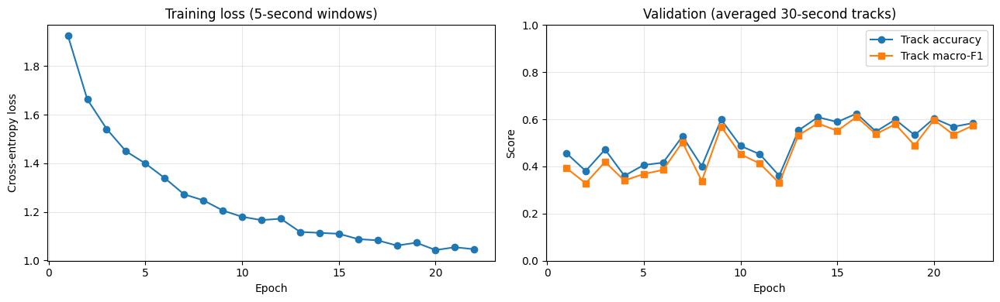

In [50]:
history_table = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_table["epoch"], history_table["train_loss"], marker="o")
axes[0].set_title("Training loss (5-second windows)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].grid(alpha=0.3)

axes[1].plot(
    history_table["epoch"],
    history_table["validation_track_accuracy"],
    marker="o",
    label="Track accuracy",
)
axes[1].plot(
    history_table["epoch"],
    history_table["validation_track_macro_f1"],
    marker="s",
    label="Track macro-F1",
)
axes[1].set_title("Validation (averaged 30-second tracks)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 12. Evaluate once on the held-out test tracks

The test set estimates performance on original tracks that were not used to fit the model or choose its checkpoint. Track-level accuracy, balanced accuracy, macro-F1, the per-genre report, and the confusion matrix summarize different aspects of performance. Balanced accuracy and macro-F1 are useful alongside accuracy because individual classes may not remain perfectly balanced after filtering and grouping.

Window-level scores are included as a diagnostic only. They are not the main result because the project goal is a prediction for an entire 30-second song.

Held-out TEST metrics — one prediction per full track
Accuracy:          0.614
Balanced accuracy: 0.618
Macro-F1:          0.612

Window-level diagnostic metrics
Window accuracy: 0.579
Window macro-F1:  0.577


,precision,recall,f1-score,support
blues,0.800,0.516,0.627,31.000
classical,0.886,1.000,0.939,31.000
country,0.682,0.500,0.577,30.000
disco,0.364,0.276,0.314,29.000
hiphop,0.714,0.741,0.727,27.000
jazz,0.609,0.519,0.560,27.000
metal,0.889,0.889,0.889,27.000
pop,0.488,0.700,0.575,30.000
reggae,0.500,0.692,0.581,26.000
rock,0.324,0.344,0.333,32.000


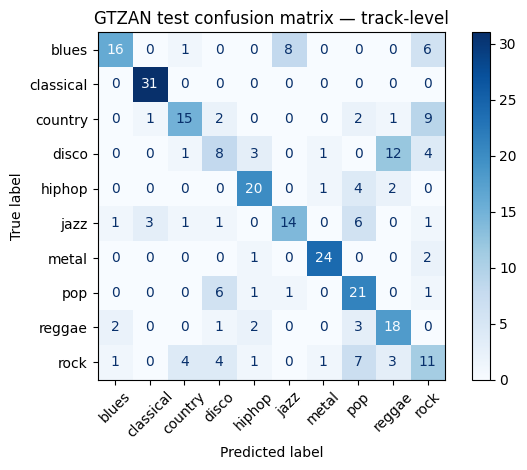

In [51]:
test_result = collect_predictions(model, test_loader, test_dataset)

test_accuracy = accuracy_score(
    test_result["track_true"],
    test_result["track_predicted"],
)
test_balanced_accuracy = balanced_accuracy_score(
    test_result["track_true"],
    test_result["track_predicted"],
)
test_macro_f1 = f1_score(
    test_result["track_true"],
    test_result["track_predicted"],
    average="macro",
    zero_division=0,
)

print("Held-out TEST metrics — one prediction per full track")
print(f"Accuracy:          {test_accuracy:.3f}")
print(f"Balanced accuracy: {test_balanced_accuracy:.3f}")
print(f"Macro-F1:          {test_macro_f1:.3f}")

print("\nWindow-level diagnostic metrics")
print(
    "Window accuracy: "
    f"{accuracy_score(test_result['window_true'], test_result['window_predicted']):.3f}"
)
print(
    "Window macro-F1:  "
    f"{f1_score(test_result['window_true'], test_result['window_predicted'], average='macro', zero_division=0):.3f}"
)

report = classification_report(
    test_result["track_true"],
    test_result["track_predicted"],
    labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)
display(pd.DataFrame(report).T.round(3))

ConfusionMatrixDisplay.from_predictions(
    test_result["track_true"],
    test_result["track_predicted"],
    labels=np.arange(len(CLASS_NAMES)),
    display_labels=CLASS_NAMES,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
)
plt.title("GTZAN test confusion matrix — track-level")
plt.tight_layout()
plt.show()

## 13. Inspect the model's track-level mistakes

Aggregate metrics can hide patterns. This table lists misclassified test tracks, sorted by the model's confidence in its chosen (incorrect) genre. Looking at these examples can reveal confusing genre pairs, inconsistent sections, or suspicious labels in the dataset.
It also shows what are the most common types of misclassifications.
And an audio player.

In [52]:
from IPython.display import Audio, HTML, display
import pandas as pd

error_rows = []

for track_index, row in enumerate(test_dataset.track_rows):
    true_id = int(test_result["track_true"][track_index])
    predicted_id = int(test_result["track_predicted"][track_index])

    if predicted_id != true_id:
        probabilities = test_result["track_probabilities"][track_index]

        error_rows.append(
            {
                "track": row["track_name"],
                "true_genre": CLASS_NAMES[true_id],
                "predicted_genre": CLASS_NAMES[predicted_id],
                "predicted_confidence": float(probabilities[predicted_id]),
                "probability_for_true_genre": float(probabilities[true_id]),
                "path": row["path"],
            }
        )

errors = pd.DataFrame(error_rows)

if errors.empty:
    print("No test tracks were misclassified in this run.")

else:
    # 1. Show the most common misclassifications
    misclassification_counts = (
      errors.groupby(["true_genre", "predicted_genre"])
      .size()
      .reset_index(name="count")
      .query("count > 1")
      .sort_values("count", ascending=False)
      .reset_index(drop=True)
  )

    print("Most common misclassifications:")
    display(misclassification_counts)

    # 2. Show all misclassified tracks with audio players
    shown = (
        errors.sort_values("predicted_confidence", ascending=False)
        .reset_index(drop=True)
        .copy()
    )

    # shown["audio"] = shown["path"].apply(
    #     lambda p: Audio(filename=str(p), embed=True)._repr_html_()
    # )

    shown = shown.drop(columns=["path"])

    print("Misclassified tracks:")
    display(
        HTML(
            shown.to_html(
                escape=False,
                index=False,
                float_format=lambda x: f"{x:.3f}",
            )
        )
    )

Most common misclassifications:


,true_genre,predicted_genre,count
0,disco,reggae,12
1,country,rock,9
2,blues,jazz,8
3,rock,pop,7
4,blues,rock,6
5,pop,disco,6
6,jazz,pop,6
7,rock,disco,4
8,rock,country,4
9,hiphop,pop,4


Misclassified tracks:


track,true_genre,predicted_genre,predicted_confidence,probability_for_true_genre
disco.00064.wav,disco,reggae,0.795,0.084
disco.00085.wav,disco,hiphop,0.684,0.068
jazz.00097.wav,jazz,classical,0.631,0.135
reggae.00052.wav,reggae,hiphop,0.584,0.044
country.00030.wav,country,classical,0.561,0.162
disco.00091.wav,disco,reggae,0.508,0.148
country.00055.wav,country,rock,0.497,0.218
pop.00093.wav,pop,disco,0.495,0.322
pop.00073.wav,pop,disco,0.489,0.305
disco.00084.wav,disco,reggae,0.481,0.215


## 14. Predict a genre for a 30-second audio file

This function applies the same audio loading, resampling, padding, mel conversion, and six-window aggregation used during training. It returns the top genre probabilities so you can see when the model is uncertain.

The example below downloads a separate sample song and compares its prediction with the known genre label. It is a prediction demo, not part of the filtered test set. For a song longer than 30 seconds, this prototype uses the first 30 seconds; a later version can compare windows throughout the whole song.


In [53]:
@torch.inference_mode()
def predict_song_genres(audio_path, top_k=3):
    log_mel = extract_log_mel(audio_path)
    windows = []
    for segment_index in range(NUM_SEGMENTS):
        start = segment_index * FRAMES_PER_SEGMENT
        window = np.array(
            log_mel[:, start : start + FRAMES_PER_SEGMENT],
            dtype=np.float32,
            copy=True,
        )
        if window.shape[1] < FRAMES_PER_SEGMENT:
            window = np.pad(
                window,
                ((0, 0), (0, FRAMES_PER_SEGMENT - window.shape[1])),
            )
        windows.append(window)

    batch = torch.from_numpy(np.stack(windows)[:, None, :, :]).to(DEVICE)
    window_probabilities = torch.softmax(model(batch), dim=1).cpu().numpy()
    track_probabilities = window_probabilities.mean(axis=0)
    ranking = np.argsort(track_probabilities)[::-1][:top_k]

    return pd.DataFrame(
        {
            "genre": [CLASS_NAMES[index] for index in ranking],
            "probability": [float(track_probabilities[index]) for index in ranking],
        }
    )

This prototype analyzes only the first 30 seconds, so its prediction may not represent a longer song whose genre changes over time.


In [54]:
from pathlib import Path
import subprocess
from urllib.parse import unquote, urlparse
from urllib.request import urlretrieve
from IPython.display import Audio, display

GITHUB_REPO_PATH = "https://raw.githubusercontent.com/Rani1281/SongGenreClassification/main/"
GITHUB_AUDIO_URL = "sample_data/rock/Do_i_Wanna_know-Artic_Monkeys.mp3"
FULL_PATH = GITHUB_REPO_PATH + GITHUB_AUDIO_URL
KNOWN_GENRE = "rock"

filename = Path(unquote(urlparse(FULL_PATH).path)).name
if not filename:
    raise ValueError("The URL must point directly to an audio file.")

download_path = Path("/content") / filename
urlretrieve(FULL_PATH, download_path)

if download_path.suffix.lower() == ".wav":
    AUDIO_PATH = download_path
else:
    AUDIO_PATH = download_path.with_suffix(".wav")
    try:
        subprocess.run(
            [
                "ffmpeg", "-hide_banner", "-loglevel", "error", "-y",
                "-i", str(download_path),
                "-vn", "-ac", "1", "-ar", str(SAMPLE_RATE),
                "-c:a", "pcm_s16le", str(AUDIO_PATH),
            ],
            check=True,
            capture_output=True,
            text=True,
        )
        print(f"Converted {download_path.name} to {AUDIO_PATH.name}")
    except subprocess.CalledProcessError as error:
        raise RuntimeError(f"Audio conversion failed: {error.stderr}") from error

display(Audio(filename=str(AUDIO_PATH)))  # Play the full song

prediction = predict_song_genres(AUDIO_PATH, top_k=3)
print(f"Audio file: {AUDIO_PATH.name}")
print(f"Actual genre: {KNOWN_GENRE}")
display(prediction.round(3))

Converted Do_i_Wanna_know-Artic_Monkeys.mp3 to Do_i_Wanna_know-Artic_Monkeys.wav


Audio file: Do_i_Wanna_know-Artic_Monkeys.wav
Actual genre: rock


,genre,probability
0,rock,0.218
1,country,0.215
2,blues,0.119


## What this prototype teaches, and what to try next

This is a useful first baseline, but its design places clear limits on the result:

- **One label only:** the ten GTZAN folders provide one target genre per track. A multi-label project needs examples with several genre labels per song, a multi-hot target vector, and a sigmoid/BCE loss instead of a single softmax/cross-entropy decision.
- **Small and imperfect data:** this notebook uses the repository's filtered manifests to omit tracks that were not selected for the experiment. The manifests and exact-copy checks do not guarantee that every near-duplicate, artist overlap, or labeling issue has been resolved.
- **A single fixed test split:** this result can vary with the split and random initialization. Later, compare several fixed seeds or use group-aware cross-validation before choosing a more complex model. Keep the manifest files fixed when comparing model changes.
- **Simple features and model:** useful experiments include changing window length, adding data augmentation, comparing MFCCs with log-mel features, trying a pretrained audio model, and tuning regularization.
- **Whole-song coverage:** for songs longer than 30 seconds, the prediction demo uses only the beginning. A later system can predict across multiple time regions and aggregate them.

Record the test metrics, class-wise scores, split manifests, and settings before each experiment. Change one major design choice at a time so you can tell what helped.
